<a href="https://colab.research.google.com/github/DanDC25/Statistical-Learning-with-Python/blob/main/%5BPractice_Trees%5D_DSA211_Simulated_Q5_Trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## How to use this question

This question is built from **Lab 10 (Tree-Based Methods), Part 1**, using the `Carseats` data from Lab 5. Lab 10 grew and pruned regression trees on `Boston`; here you run the same code on `Carseats`, where `Sales` is the response. Every step has been done in a lab.

- Work like the exam: about **18 minutes**, open book, no AI.
- For each part, find the matching lab cell, adapt the code, run it, then write your answer in the markdown cell under the part label.
- Keep to the sentence limits. A printed number with no sentence earns at most half the marks.
- Importing the libraries you need is part of the task. The **📍 Where to look** note under each part says which lab cell to open, including the Setup cell with the imports. Try first, then look.

***

## Setup

Run as given. It loads `Carseats` as in Lab 5, encodes the categorical predictors as in Lab 10, Part 2, and makes one 70/30 split, as in Lab 10, Part 0. `Sales` is in thousands of units. Use `X_train`, `y_train` for every choice, and touch `X_test`, `y_test` once, in 5(d).

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

url = 'https://raw.githubusercontent.com/intro-stat-learning/ISLP/main/ISLP/data/Carseats.csv'
carseats = pd.read_csv(url)
carseats.index = range(1, len(carseats) + 1)

X = pd.get_dummies(carseats.drop(columns='Sales'), drop_first=True).astype(float)
y = carseats['Sales']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2026)

print(X.columns.tolist())
print(f"Training: {len(X_train)} stores, test: {len(X_test)} stores")

['CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'Age', 'Education', 'ShelveLoc_Good', 'ShelveLoc_Medium', 'Urban_Yes', 'US_Yes']
Training: 280 stores, test: 120 stores


Use `KFold(n_splits=5, shuffle=True, random_state=2026)` and `random_state=2026` in every tree.

***

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     cross_val_score)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, accuracy_score, confusion_matrix

**5(a)** Fit a regression tree of depth 2 to the training set and plot it. Which predictor does the tree split on first, and at what value? What does the second level of splits tell you about how that predictor and `Price` work together? **[2]** *(at most 3 sentences)*

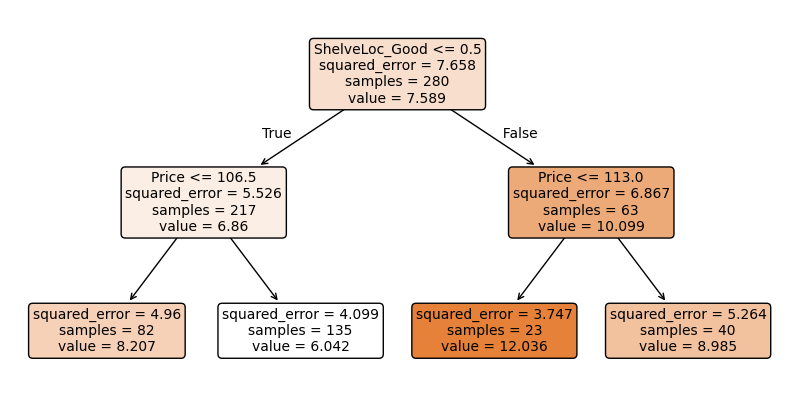

In [3]:
### YOUR CODE HERE
small_tree = DecisionTreeRegressor(max_depth=2,
                                   random_state=2026)
small_tree.fit(X_train, y_train);

fig, ax = plt.subplots(figsize=(10, 5))
plot_tree(small_tree,
          feature_names=list(X_train.columns),
          filled=True,
          rounded=True,
          fontsize=10, ax=ax)
plt.show()

**5(a)**

*Your answer here:*

The tree first splits using predictor "ShelveLoc", otherwise known as Shelve location, as ShelveLoc_good is a binary variable that returns 1 if the shelve location is good and 0 otherwise, the tree first splits by determining if observations have ShelveLoc_Good <= 0.5 where true means shelve location isn't good and false mean shelve location is good.

It appears that after the first split, the tree utilizes the predictor "Price" in the second split. This tells me that eventhough price is the primary driver of sales, prices are heavily dicated by Shelve Location quality also. Specifically, if the shelvelocation is good, prices could be higher.



> 📍 **Where to look**
>
> - **Imports:** Lab 10, **Part 0: Setup and Data** (first code cell).
> - **Code:** Lab 10, **1.1 A First Tree** (`DecisionTreeRegressor(max_depth=2, ...)` and `plot_tree`).
> - **Reasoning:** Lab 10, **Question 1.1a** (the first split, and what it means when both branches split on the same variable at different values).

***

**5(b)** For trees of depth 2, 3 and unlimited depth, report the number of leaves, the training MSE and the 5-fold CV MSE. Rank the three trees by training MSE and by CV MSE. Do the rankings agree, and what does the unlimited tree show? **[2]** *(at most 3 sentences)*

In [9]:
### YOUR CODE HERE
results_list = []

cv = KFold(n_splits=5,
shuffle=True,
random_state=2026)

for label, depth in [('Depth-2 tree', 2), ('Depth-3 tree', 3), ('Fully grown tree', None)]:
  model = DecisionTreeRegressor(max_depth=depth,random_state=2026)
  model.fit(X_train, y_train)
  mse = mean_squared_error(y_train, model.predict(X_train))
  CV_MSE = -cross_val_score(model, X_train, y_train, cv=cv, scoring='neg_mean_squared_error').mean()
  results_list.append({
        'Model': label,
        'Number of leaves': model.get_n_leaves(),
        'Training MSE': mse,
        'CV MSE': CV_MSE})

results = pd.DataFrame(results_list).set_index('Model')
print(results)

                  Number of leaves  Training MSE    CV MSE
Model                                                     
Depth-2 tree                     4      4.488557  5.688548
Depth-3 tree                     8      3.390484  5.074555
Fully grown tree               279      0.000000  5.126625


**5(b)**
Do the rankings agree, and what does the unlimited tree show?
*Your answer here:*

The rankings do not, in fact, agree. It's expected that as number of leaves increase (more complex models), both training MSE and CV MSE decreases.

However, evident in the output, the Depth-3 tree outperforms Fully-grown tree who we had anticipated to perform the best; perhaps it's because the fully grown tree possesses 279 leaves, and severely overfitting.

> 📍 **Where to look**
>
> - **Code:** Lab 10, **Exercise 1.1: Training error vs CV error** (the `cv = KFold(...)` cell, then the loop over `[2, 3, None]`).
> - **Reasoning:** Lab 10, **Question 1.1b**.

***

**5(c)** Prune by cost-complexity using 5-fold CV on the training set. Report the number of leaves, CV MSE and SE of the CV-minimum tree, and the number of leaves and CV MSE of the one-standard-error tree. Which do you carry forward, and why? **[2]** *(at most 3 sentences)*

In [23]:
### YOUR CODE HERE
full_tree = DecisionTreeRegressor(random_state=2026)
alphas = full_tree.cost_complexity_pruning_path(X_train, y_train).ccp_alphas[:-1]

cv_mse, cv_se, n_leaves = [], [], []
for a in alphas:
    model = DecisionTreeRegressor(ccp_alpha=a,
                                  random_state=2026)
    mse = -cross_val_score(model,
                           X_train,
                           y_train,
                           cv=cv,
                           scoring='neg_mean_squared_error')
    cv_mse.append(mse.mean())
    cv_se.append(mse.std(ddof=1) / np.sqrt(len(mse)))
    n_leaves.append(model.fit(X_train, y_train).get_n_leaves())

cv_mse, cv_se, n_leaves = map(np.array, (cv_mse, cv_se, n_leaves))
best = cv_mse.argmin()
#print(f'{len(alphas)} candidate alphas') use if needed
print(f'CV minimum tree: {n_leaves[best]} leaves, CV MSE {cv_mse[best]:.2f} (SE {cv_se[best]:.2f})')

leaves_CVMSE = []

threshold = cv_mse[best] + cv_se[best]
candidates = np.where(cv_mse <= threshold)[0]
i_1se = candidates[n_leaves[candidates].argmin()]
alpha_1se = alphas[i_1se]
tree_1se = DecisionTreeRegressor(ccp_alpha=alpha_1se, random_state=2026)
tree_1se.fit(X_train, y_train)

mse2 = -cross_val_score(tree_1se, X_train, y_train, cv=cv, scoring='neg_mean_squared_error')

num_leaves = tree_1se.get_n_leaves()
cv_mse2 = mse2.mean()
#se_1se = mse2.std(ddof=1) / np.sqrt(len(mse2)) use if asked for SE of 1se tree

print(f'\nOne standard error tree: {num_leaves} leaves, CV MSE {cv_mse2:2f}')


CV minimum tree: 41 leaves, CV MSE 4.65 (SE 0.40)

One standard error tree: 22 leaves, CV MSE 4.957397


**5(c)**

*Your answer here:*

Comparing the one-SE tree and the CV-minimum tree, the one-SE tree has higher CV MSE at (4.9574> 4.65). However, in turn, the one-SE tree has less number of leave (22) compared to 41 leaves. Here, we give up some CV-MSE, that is, error, in return for less model complexity to avoid overfitting on new test-set. Thus, I choose to carry forward the one-standard-error tree as it's less complex than the CV minimum tree while I give up a small number of CV MSE.

> 📍 **Where to look**
>
> - **Code:** Lab 10, **1.2 Pruning by Cross-Validation** (the loop over `ccp_alphas` that stores `cv_mse`, `cv_se`, `n_leaves`), then **Exercise 1.2: The one-SE tree**.
> - **Reasoning:** Lab 10, **Question 1.2**, and Lab 8, **4.1 The One-Standard-Error Rule**.

***

**5(d)** Touch the test set once with your carried-forward tree. Report the test MSE and RMSE, compare the test MSE with the tree's CV MSE, and interpret the RMSE in the units of `Sales`. **[2]** *(at most 3 sentences)*

In [24]:
### YOUR CODE HERE
MSE = mean_squared_error(y_test, tree_1se.predict(X_test))
RMSE = np.sqrt(MSE)
final_tree = DecisionTreeRegressor(ccp_alpha=alpha_1se, random_state=2026).fit(X, y)
print(f'The number of leaves of the final tree is {final_tree.get_n_leaves()}')
print(f'Test MSE is {MSE:.2f}, and test RMSE is {RMSE:.2f}')

The number of leaves of the final tree is 29
Test MSE is 6.14, and test RMSE is 2.48


**5(d)**

*Your answer here:*

Despite coming from the same tree, the test MSE is higher than the CV MSE on training data, respectively 6.14 > 4.97574.

On average, our tree's prediction of child car seat sales at a given store deviate from the actual sales by 2480 units.

(The number reported in the tree regression of is currently log-transformed. In order to report as a genralization estimate, we must use the TEST MSE or test RMSE, NOT the training CV MSE. It's not estimated after the refit because we no longer have an independent, untouched test set left to estimate generalization. If there is, let's say a new dataset, we would be able to estimate generalization.) **DELETE IF NOT USING**

> 📍 **Where to look**
>
> - **Code:** Lab 10, **Exercise 1.3: Test MSE and the final tree**.
> - **Reasoning:** Lab 10, **Question 1.3**.

***

**5(e)** Compute the 5-fold CV MSE of a linear regression on the same training set and folds. Which model wins, by how much, and why is the result the opposite of Lab 10's `Boston` comparison? **[2]** *(at most 3 sentences)*

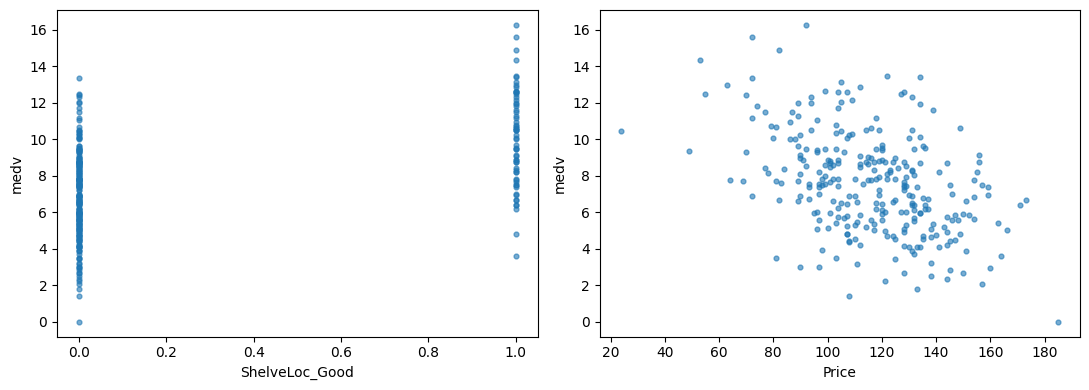

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, col in zip(ax, ['ShelveLoc_Good', 'Price']):
    a.scatter(X_train[col], y_train, s=12, alpha=0.6)
    a.set_xlabel(col)
    a.set_ylabel('Sales')
plt.tight_layout()
plt.show()


In [31]:
### YOUR CODE HERE
lin_mse = -cross_val_score(LinearRegression(),
                           X_train,
                           y_train,
                           cv=cv,
                           scoring='neg_mean_squared_error').mean()

print(f'One-SE tree CV MSE:       {cv_mse[i_1se]:.2f}')  # or {cv_mse2:2f}
print(f'Linear regression CV MSE: {lin_mse:.2f}')

One-SE tree CV MSE:       4.96
Linear regression CV MSE: 1.08


**5(e)**

*Your answer here:*

Here, we can see that the linear regression wins over the tree regressiom, with the one-standard-error rule applied. Evidently, the CV MSE of Linear Regression is 1.08 which is smaller than the OneSE tree's CV MSE at 4.96.

Perhaps it's because the Boston dataset fits a step function more than a linear function whereas our Carseats dataset fir a linear function more. Perhaps it's because the relationship between Price and Sales are non linear, which in this context, a linear function excels at modelling the relationship than a step-function Tree Regression.



> 📍 **Where to look**
>
> - **Code:** Lab 10, **1.4 Tree vs Linear Regression** (the `lin_mse = -cross_val_score(LinearRegression(), ...)` cell).
> - **Reasoning:** Lab 10, **Question 1.4**. Its answer contrasts `Boston` with `Carseats`. Look at how `Sales` responds to `Price` in the Lab 5 EDA (Part 0).

***

## After you finish

Check yourself against the lab, not against a friend's notebook:

1. Did every figure you quoted come from your own printed output?
2. Did every part get a written answer, not only code?
3. Which parts needed the lab open? Those cells are the ones to rehearse before the exam.